# 01 · Data Understanding
**Project:** Bank Marketing Campaign Analysis (Term Deposit Subscription)

**Goal of this notebook:** get oriented with the raw data — what each column means, how big the data is, how imbalanced the target is, and where data-quality problems hide.

**Data:** Direct-marketing (phone) campaigns of a Portuguese bank, 2008–2010 (Moro, Cortez & Rita, UCI Machine Learning Repository, `bank-additional-full`). One row = one customer contact. Target `y` = did the customer subscribe to a term deposit?

In [4]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("..")
FIG, TAB = ROOT / "outputs/figures", ROOT / "outputs/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

NAVY, TEAL, ORANGE, GREY = "#1F3A5F", "#2A9D8F", "#E76F51", "#9AA5B1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 140)

In [5]:
df = pd.read_csv(ROOT / "data/bank_marketing.csv", sep=";")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 41,188   Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Data dictionary

In [6]:
dictionary = pd.DataFrame([
 ("age","Customer","numeric","Age in years"),
 ("job","Customer","categorical","Type of job (12 categories)"),
 ("marital","Customer","categorical","Marital status"),
 ("education","Customer","categorical","Education level"),
 ("default","Customer","categorical","Has credit in default? (yes / no / unknown)"),
 ("housing","Customer","categorical","Has housing loan?"),
 ("loan","Customer","categorical","Has personal loan?"),
 ("contact","Current campaign","categorical","Contact channel: cellular / telephone"),
 ("month","Current campaign","categorical","Month of last contact"),
 ("day_of_week","Current campaign","categorical","Weekday of last contact"),
 ("duration","Current campaign","numeric","Last call duration in seconds (only known AFTER the call - leakage risk)"),
 ("campaign","Current campaign","numeric","Number of contacts to this client during this campaign"),
 ("pdays","Previous campaign","numeric","Days since last contact in a previous campaign (999 = never contacted)"),
 ("previous","Previous campaign","numeric","Number of contacts before this campaign"),
 ("poutcome","Previous campaign","categorical","Outcome of the previous campaign"),
 ("emp.var.rate","Macro-economy","numeric","Employment variation rate (quarterly)"),
 ("cons.price.idx","Macro-economy","numeric","Consumer price index (monthly)"),
 ("cons.conf.idx","Macro-economy","numeric","Consumer confidence index (monthly)"),
 ("euribor3m","Macro-economy","numeric","Euribor 3-month rate (daily)"),
 ("nr.employed","Macro-economy","numeric","Number of employees in the economy (quarterly)"),
 ("y","Target","binary","Subscribed to a term deposit? (yes / no)"),
], columns=["column","group","type","description"])
dictionary.to_csv(TAB / "01_data_dictionary.csv", index=False)
dictionary

,column,group,type,description
0,age,Customer,numeric,Age in years
1,job,Customer,categorical,Type of job (12 categories)
2,marital,Customer,categorical,Marital status
3,education,Customer,categorical,Education level
4,default,Customer,categorical,Has credit in default? (yes / no / unknown)
5,housing,Customer,categorical,Has housing loan?
6,loan,Customer,categorical,Has personal loan?
7,contact,Current campaign,categorical,Contact channel: cellular / telephone
8,month,Current campaign,categorical,Month of last contact
9,day_of_week,Current campaign,categorical,Weekday of last contact


## 2. Structure, types and missing values

In [7]:
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(),
                     "n_unique": df.nunique()})
display(info)
print("Explicit missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows   :", int(df.duplicated().sum()))

,dtype,non_null,n_unique
age,int64,41188,78
job,str,41188,12
marital,str,41188,4
education,str,41188,8
default,str,41188,3
housing,str,41188,3
loan,str,41188,3
contact,str,41188,2
month,str,41188,10
day_of_week,str,41188,5


Explicit missing values: 0
Exact duplicate rows   : 12


**Hidden missing data.** There are no `NaN`s, but several categorical columns encode missing information as the literal string `"unknown"`, and `pdays` uses the sentinel value `999`.

In [8]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("y")
unk = pd.DataFrame({"unknown_count": [(df[c] == "unknown").sum() for c in cat_cols]}, index=cat_cols)
unk["unknown_pct"] = (unk.unknown_count / len(df) * 100).round(2)
unk = unk[unk.unknown_count > 0].sort_values("unknown_pct", ascending=False)
unk.to_csv(TAB / "01_unknown_values.csv")
print(f"pdays == 999 (never contacted before): {(df.pdays == 999).mean():.1%}")
unk

pdays == 999 (never contacted before): 96.3%


,unknown_count,unknown_pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


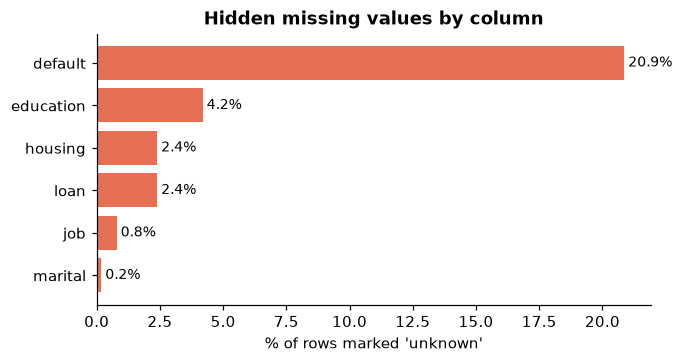

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(unk.index[::-1], unk.unknown_pct[::-1], color=ORANGE)
for i, v in enumerate(unk.unknown_pct[::-1]): ax.text(v + .15, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of rows marked 'unknown'"); ax.set_title("Hidden missing values by column")
fig.savefig(FIG / "01_unknown_values.png"); plt.show()

## 3. Target variable

,customers,share_pct
y,,
no,36548,88.73
yes,4640,11.27


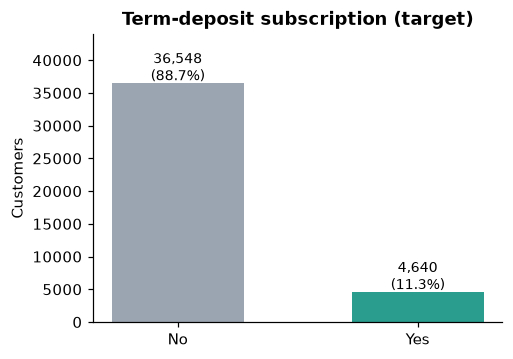

In [10]:
tgt = df.y.value_counts().rename_axis("y").to_frame("customers"); tgt["share_pct"] = (tgt.customers / len(df) * 100).round(2)
tgt.to_csv(TAB / "01_target_distribution.csv"); display(tgt)

fig, ax = plt.subplots(figsize=(4.8, 3.4))
bars = ax.bar(["No", "Yes"], tgt.loc[["no", "yes"], "customers"], color=[GREY, TEAL], width=.55)
for b, p in zip(bars, tgt.loc[["no", "yes"], "share_pct"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 400, f"{b.get_height():,.0f}\n({p:.1f}%)", ha="center", fontsize=9)
ax.set_ylim(0, 44000); ax.set_ylabel("Customers"); ax.set_title("Term-deposit subscription (target)")
fig.savefig(FIG / "01_target_distribution.png"); plt.show()

## 4. Summary statistics

In [11]:
num = df.select_dtypes("number")
stats = num.describe().T.round(2); stats["skew"] = num.skew().round(2)
stats.to_csv(TAB / "01_numeric_summary.csv"); stats

,count,mean,std,min,25%,50%,75%,max,skew
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00,0.78
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00,3.26
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00,4.76
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00,-4.92
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00,3.83
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40,-0.72
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77,-0.23
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90,0.30
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04,-0.71
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10,-1.04


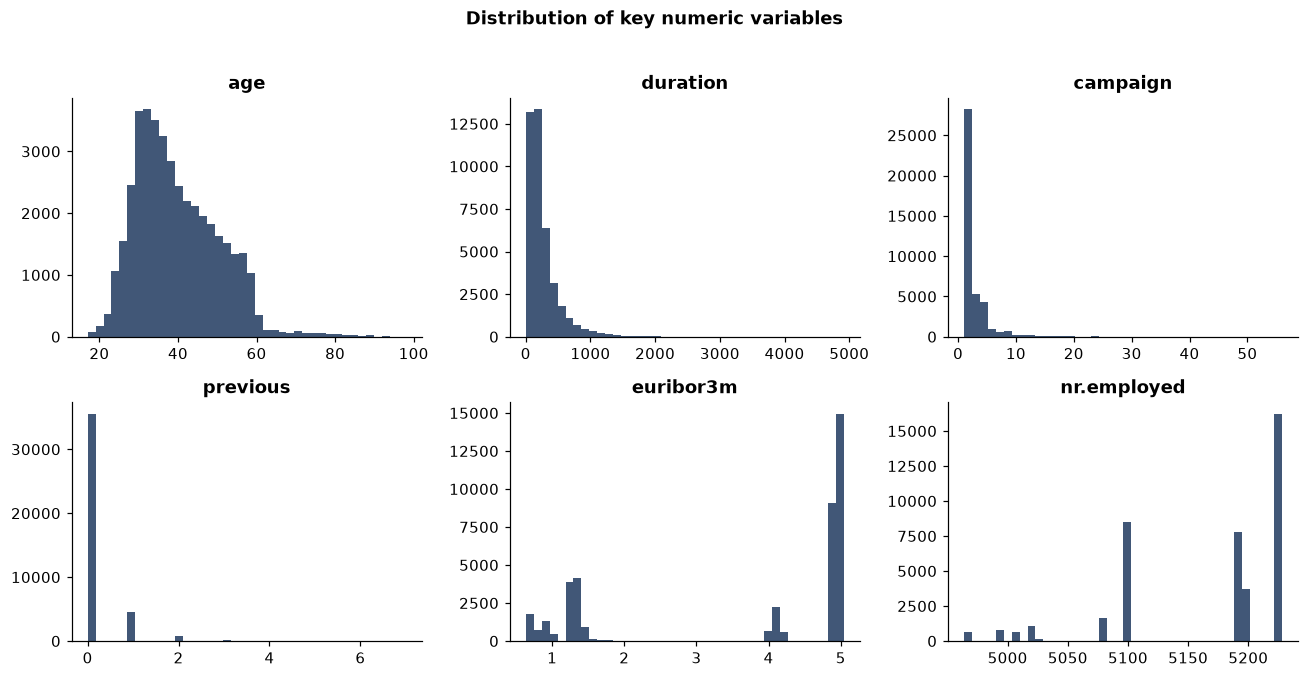

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), ["age", "duration", "campaign", "previous", "euribor3m", "nr.employed"]):
    ax.hist(df[col], bins=40, color=NAVY, alpha=.85); ax.set_title(col)
fig.suptitle("Distribution of key numeric variables", fontweight="bold", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "01_numeric_distributions.png"); plt.show()

## 5. Things to handle in the next notebook
* `duration` is only known after the call ends → **must not** be used in a model meant to decide *whom to call*.
* `pdays = 999` is a sentinel for "never contacted" → convert to a flag.
* `unknown` categories (esp. `default`, `education`) → keep as their own level, since missingness itself may be informative.
* Heavy right-skew in `campaign` and `duration` → cap outliers.
* A few exact duplicate rows → drop.
* Severe class imbalance (~11% positives) → use ranking metrics (ROC-AUC, PR-AUC, lift), not accuracy.

## Key takeaways
* **41,188 contacts × 21 columns**, no explicit NaNs, 12 exact duplicates.
* **Only 11.3% subscribed** (4,639 customers) → strongly imbalanced target.
* Hidden missingness: `default` is "unknown" for **20.9%** of customers, `education` 4.2%, `housing`/`loan` 2.4%; **96.3%** of customers were never contacted in a prior campaign (`pdays = 999`).
* `duration` is a leakage variable and `campaign`/`duration` are heavily right-skewed.